# German Credit Risk Scoring — Full Technical Analysis

**FinTech Masterclass | Final Project**  
**Primary source:** `german.data` + accompanying `german.doc`  
**Target convention:** `0 = Good` (good credit), `1 = Bad` (bad credit)  
**Decision-cost assumption:** False Negative (Bad predicted Good) = 5; False Positive (Good predicted Bad) = 1.

## Project purpose and scope
This notebook implements the complete analysis requested in `PRI_masterclass-final-project.pdf`: data audit and EDA; feature engineering and leakage-safe preprocessing; baseline/challenger modeling and validation; confusion-matrix and asymmetric-cost analysis; global and local SHAP explanations; written causality-versus-correlation analysis; and a proposed LLM/adverse-action prompt with a clearly labeled illustrative response.

**Important scope boundary.** This is an educational risk-ranking experiment, not a lending policy or production-ready credit decision system. The dataset is historical and observational. It does not supply a modern default observation horizon, full repayment history, verified income, liabilities, or debt-to-income ratio. Statistical association and SHAP attribution are not causal evidence.

### Reproducibility and evidence labels
- The approved analysis used the fixed split `test_size=0.20`, `stratify=y`, `random_state=42`, a 5-fold stratified CV, and the Random Forest configuration reproduced below.
- The previously approved operating threshold **0.216** is frozen for the principal holdout comparison. The saved prior OOF probability vector was not part of the supplied artifacts; therefore this notebook does **not** claim to independently reconstruct the historical threshold-selection event. It does reproduce the reported holdout metrics from the exact data split and model configuration.
- A separate training-only hyperparameter search is included as a sensitivity exercise. It does not replace the frozen benchmark or trigger a second use of the test set.
- All tables, figures, model scores, SHAP values, and regression results below are generated from the source file when the notebook is executed top-to-bottom.

## 0. Research question, target, and decision context

The prediction target is the dataset class label, not a rigorously observed modern default event. The project asks whether available applicant attributes can rank the likelihood of the historical `Bad` class and how a decision threshold changes the relative number of missed Bad cases and falsely flagged Good cases. The cost ratio 5:1 is supplied as an educational assumption; it is not a complete bank profit, loss, capital, fairness, or regulatory objective.

In [ ]:
from pathlib import Path
import warnings, sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, pointbiserialr
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, balanced_accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report, RocCurveDisplay, PrecisionRecallDisplay)
from IPython.display import display

RANDOM_STATE = 42
DATA_PATH = Path('german.data')
COST_FN, COST_FP = 5, 1
APPROVED_RF_THRESHOLD = 0.216
print('Python:', sys.version.split()[0], '| Platform:', platform.platform())
print('NumPy:', np.__version__, '| pandas:', pd.__version__)

Python: 3.12.1 | Platform: Windows-10-10.0.19045-SP0
NumPy: 2.5.4 | pandas: 2.3.3


## 1. Source files, column dictionary, and data loading

The accompanying documentation states that the original symbolic dataset contains 1,000 observations, 20 attributes (7 numerical and 13 categorical). The alternate `german.data-numeric` file was created for algorithms requiring numerical input and contains edited/indicator-coded attributes. Consequently, `german.data` is the sole modeling source; the numeric variant is a validation/reference file only.

In [2]:
columns = [
    'checking_account','duration_months','credit_history','purpose','credit_amount',
    'savings_account','employment_since','installment_rate','personal_status_sex',
    'other_debtors_guarantors','residence_since','property','age_years',
    'other_installment_plans','housing','existing_credits','job','dependents',
    'telephone','foreign_worker','target_raw'
]
df = pd.read_csv(DATA_PATH, sep=r'\s+', header=None, names=columns)
assert df.shape == (1000, 21), f'Unexpected source shape: {df.shape}'
assert set(df.target_raw.unique()) == {1, 2}, 'Unexpected target labels'
df['target'] = (df.target_raw == 2).astype(int)  # 0=Good, 1=Bad
numeric_original = ['duration_months','credit_amount','installment_rate','residence_since','age_years','existing_credits','dependents']
categorical = [c for c in columns[:-1] if c not in numeric_original]
print('Shape including raw target:', df.shape)
print('Numeric predictors:', len(numeric_original), numeric_original)
print('Categorical predictors:', len(categorical), categorical)
display(df.head())

Shape including raw target: (1000, 22)
Numeric predictors: 7 ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'age_years', 'existing_credits', 'dependents']
Categorical predictors: 13 ['checking_account', 'credit_history', 'purpose', 'savings_account', 'employment_since', 'personal_status_sex', 'other_debtors_guarantors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors_guarantors,...,age_years,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,target_raw,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,67,A143,A152,2,A173,1,A192,A201,1,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,22,A143,A152,1,A173,1,A191,A201,2,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,49,A143,A152,1,A172,2,A191,A201,1,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,45,A143,A153,1,A173,2,A191,A201,1,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,53,A143,A153,2,A173,2,A191,A201,2,1


### Dataset codebook — original `german.doc`

The table below preserves the attribute meaning and category codes in the supplied documentation. Numeric/ordinal attributes are: Duration (months), Credit Amount (DM), Installment Rate (% of disposable income), Residence Since, Age (years), Existing Credits at this bank, and Dependents. The remaining 13 fields are categorical.

| Attribute | Meaning | Documented category codes |
|---|---|---|
| Checking Account | Existing checking-account status | A11: below 0 DM; A12: 0–below 200 DM; A13: at least 200 DM or salary assignment ≥1 year; A14: no checking account |
| Credit History | Previous credit repayment history | A30: no credits/all duly paid; A31: all credits at this bank duly paid; A32: existing credits duly paid; A33: past delay; A34: critical account/other credits |
| Purpose | Loan purpose | A40: new car; A41: used car; A42: furniture/equipment; A43: radio/TV; A44: domestic appliances; A45: repairs; A46: education; A47: vacation (documented as “does not exist?”); A48: retraining; A49: business; A410: others |
| Savings Account | Savings account/bonds | A61: below 100 DM; A62: 100–below 500 DM; A63: 500–below 1,000 DM; A64: at least 1,000 DM; A65: unknown/no savings account |
| Employment Since | Present employment duration | A71: unemployed; A72: below 1 year; A73: 1–below 4 years; A74: 4–below 7 years; A75: at least 7 years |
| Personal Status & Sex | Personal status and sex | A91: male divorced/separated; A92: female divorced/separated/married; A93: male single; A94: male married/widowed; A95: female single (not observed in this file) |
| Other Debtors / Guarantors | Additional debtor or guarantor | A101: none; A102: co-applicant; A103: guarantor |
| Property | Property type | A121: real estate; A122: building-society savings/life insurance (if not A121); A123: car/other (if not A121/A122); A124: unknown/no property |
| Other Installment Plans | Other installment plans | A141: bank; A142: stores; A143: none |
| Housing | Housing situation | A151: rent; A152: own; A153: for free |
| Job | Job category | A171: unemployed/unskilled non-resident; A172: unskilled resident; A173: skilled employee/official; A174: management/self-employed/highly qualified/officer |
| Telephone | Telephone status | A191: none; A192: yes, registered in customer’s name |
| Foreign Worker | Foreign worker flag | A201: yes; A202: no |

`A47` and `A95` are documented but absent from the observed source. They are not synthesized. The original documentation also specifies a 2×2 cost matrix with rows=actual and columns=predicted: `[[0,1],[5,0]]` for Good/Bad. Thus the costly error is predicting Good for an actual Bad case (FN=5); predicting Bad for an actual Good case costs 1 (FP=1).

## 2. Initial data audit and quality controls

The audit checks dimensions, missingness, duplicate records, target coding, data types, numeric ranges, and category frequencies. Outlier flags are diagnostic only: a statistical rule does not prove a record is erroneous. The documented missing category codes `A47` (Purpose) and `A95` (Personal Status & Sex) were not observed; they are not artificially inserted.

In [3]:
audit = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_n': df.isna().sum(),
    'missing_pct': (df.isna().mean()*100).round(2),
    'n_unique': df.nunique(dropna=True)
})
display(audit)
print('Duplicate complete rows:', int(df.duplicated().sum()))
print('Missing cells:', int(df.isna().sum().sum()))
print('Raw target counts:', df.target_raw.value_counts().sort_index().to_dict())
print('Standardized target counts:', df.target.value_counts().sort_index().to_dict())
print('Observed Purpose codes:', sorted(df.purpose.unique()))
print('Observed Personal Status & Sex codes:', sorted(df.personal_status_sex.unique()))
assert df.isna().sum().sum() == 0 and df.duplicated().sum() == 0

,dtype,missing_n,missing_pct,n_unique
checking_account,object,0,0.0,4
duration_months,int64,0,0.0,33
credit_history,object,0,0.0,5
purpose,object,0,0.0,10
credit_amount,int64,0,0.0,921
savings_account,object,0,0.0,5
employment_since,object,0,0.0,5
installment_rate,int64,0,0.0,4
personal_status_sex,object,0,0.0,4
other_debtors_guarantors,object,0,0.0,3


Duplicate complete rows: 0
Missing cells: 0
Raw target counts: {1: 700, 2: 300}
Standardized target counts: {0: 700, 1: 300}
Observed Purpose codes: ['A40', 'A41', 'A410', 'A42', 'A43', 'A44', 'A45', 'A46', 'A48', 'A49']
Observed Personal Status & Sex codes: ['A91', 'A92', 'A93', 'A94']


Numeric range and descriptive audit. Several integer-valued fields are ordinal/discrete, not continuous.

In [4]:
display(df[numeric_original].describe().T)
for col in categorical:
    print(f'\n{col}:')
    display(df[col].value_counts(dropna=False).rename('count').to_frame())

,count,mean,std,min,25%,50%,75%,max
duration_months,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age_years,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0



checking_account:


,count
checking_account,
A14,394
A11,274
A12,269
A13,63



credit_history:


,count
credit_history,
A32,530
A34,293
A33,88
A31,49
A30,40



purpose:


... (17 outputs left out)


telephone:


,count
telephone,
A191,596
A192,404



foreign_worker:


,count
foreign_worker,
A201,963
A202,37


### Audit decision
No missing values, duplicate complete rows, malformed rows, invalid target labels, or invalid observed numeric values were found in the primary source. Therefore no imputation, row deletion, or outlier deletion is justified. The seven numeric-like columns include ordinal/discrete scales (for example installment rate and residence since); treating all of them as continuous measurements would be misleading.

## 3. Exploratory Data Analysis (EDA)

The required EDA includes target imbalance, distributions of loan amount and duration, boxplot-based outlier screening, numerical association, and categorical association with the target. Cramér’s V is used as an effect-size summary for categorical features; p-values are exploratory and should be interpreted cautiously in sparse contingency tables.

Target balance and imbalance ratio

          count share
Good (0)    NaN   NaN
Bad (1)     NaN   NaN
Good:Bad ratio = 2.333 : 1


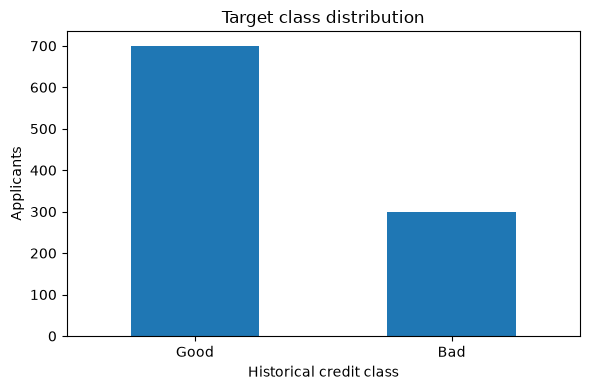

In [5]:
counts = df.target.value_counts().sort_index()
props = df.target.value_counts(normalize=True).sort_index()
print(pd.DataFrame({'count':counts, 'share':props.map(lambda x:f'{x:.1%}')}, index=['Good (0)','Bad (1)']))
print('Good:Bad ratio =', round(counts.loc[0]/counts.loc[1], 3), ': 1')
fig, ax = plt.subplots(figsize=(6,4)); counts.rename(index={0:'Good',1:'Bad'}).plot(kind='bar',ax=ax)
ax.set_title('Target class distribution'); ax.set_ylabel('Applicants'); ax.set_xlabel('Historical credit class'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

Distributions of core numeric variables and IQR outlier flags

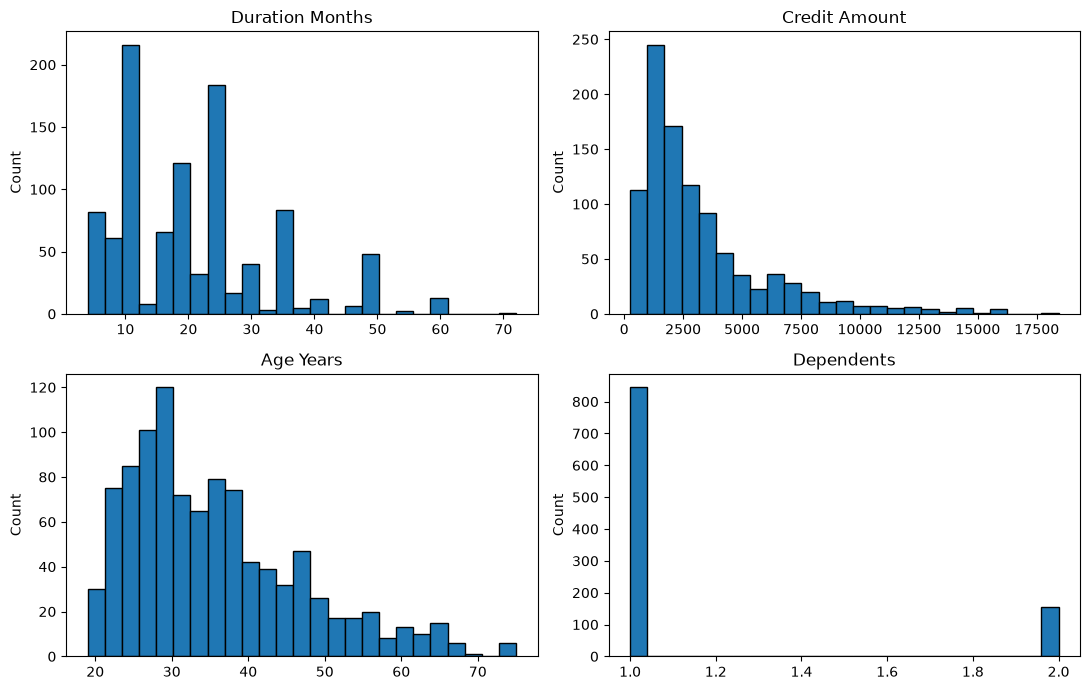

,feature,Q1,Q3,IQR,lower_fence,upper_fence,flagged_n
0,duration_months,12.0,24.00,12.00,-6.000,42.000,70
1,credit_amount,1365.5,3972.25,2606.75,-2544.625,7882.375,72
2,installment_rate,2.0,4.00,2.00,-1.000,7.000,0
3,residence_since,2.0,4.00,2.00,-1.000,7.000,0
4,age_years,27.0,42.00,15.00,4.500,64.500,23
5,existing_credits,1.0,2.00,1.00,-0.500,3.500,6
6,dependents,1.0,1.00,0.00,1.000,1.000,155


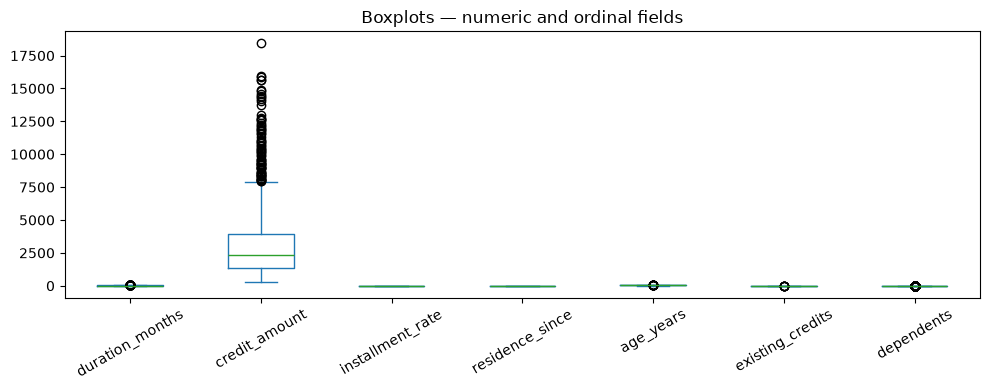

In [ ]:
fig, axes = plt.subplots(2,2,figsize=(11,7))
for col, ax in zip(['duration_months','credit_amount','age_years','dependents'], axes.ravel()):
    ax.hist(df[col], bins=25, edgecolor='black'); ax.set_title(col.replace('_',' ').title()); ax.set_ylabel('Count')
plt.tight_layout(); plt.show()

outlier_rows=[]
for col in numeric_original:
    q1,q3=df[col].quantile([.25,.75]); iqr=q3-q1
    lo,hi=q1-1.5*iqr,q3+1.5*iqr
    n=int(((df[col]<lo)|(df[col]>hi)).sum())
    outlier_rows.append({'feature':col,'Q1':q1,'Q3':q3,'IQR':iqr,'lower_fence':lo,'upper_fence':hi,'flagged_n':n})
outlier_table=pd.DataFrame(outlier_rows)
display(outlier_table)
fig, ax=plt.subplots(figsize=(10,4)); df[numeric_original].plot(kind='box',ax=ax,rot=30); ax.set_title('Boxplots — numeric and ordinal fields'); plt.tight_layout(); plt.show()

### Outlier interpretation
The IQR rule flags 70 Duration values, 72 Credit Amount values, 23 Age values, 6 Existing Credits values, and 155 Dependents values; Installment Rate and Residence Since have no IQR flags. Dependents has Q1=Q3=1 and IQR=0, so values of 2 are mechanically flagged despite being valid observed categories. These flags are not evidence of data corruption. No records were removed or winsorized.

Numeric correlations with target and among selected numeric fields

,duration_months,credit_amount,installment_rate,residence_since,age_years,existing_credits,dependents,target
duration_months,1.000,0.625,0.075,0.034,-0.036,-0.011,-0.024,0.215
credit_amount,0.625,1.000,-0.271,0.029,0.033,0.021,0.017,0.155
installment_rate,0.075,-0.271,1.000,0.049,0.058,0.022,-0.071,0.072
residence_since,0.034,0.029,0.049,1.000,0.266,0.090,0.043,0.003
age_years,-0.036,0.033,0.058,0.266,1.000,0.149,0.118,-0.091
existing_credits,-0.011,0.021,0.022,0.090,0.149,1.000,0.110,-0.046
dependents,-0.024,0.017,-0.071,0.043,0.118,0.110,1.000,-0.003
target,0.215,0.155,0.072,0.003,-0.091,-0.046,-0.003,1.000


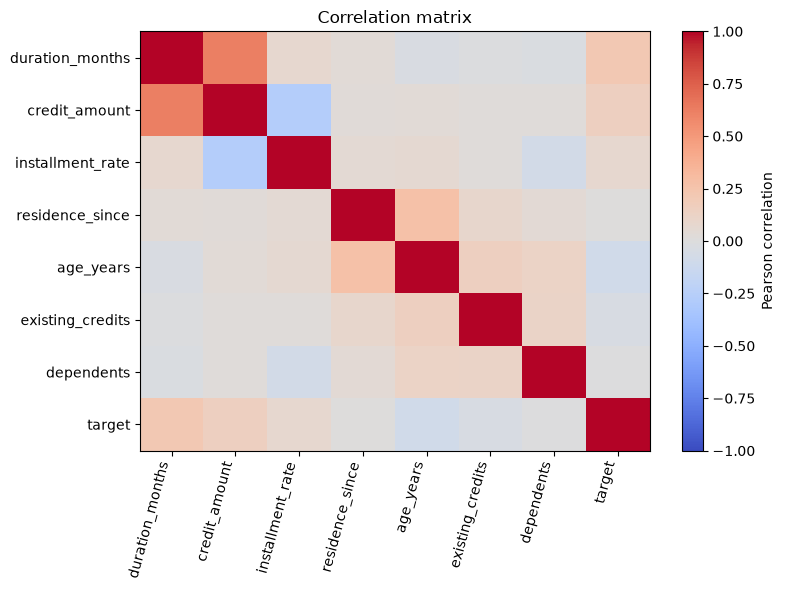

In [7]:
corr = df[numeric_original+['target']].corr(numeric_only=True)
display(corr.round(3))
fig,ax=plt.subplots(figsize=(8,6)); im=ax.imshow(corr,aspect='auto',vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr.columns)),corr.columns,rotation=75,ha='right'); ax.set_yticks(range(len(corr.index)),corr.index)
fig.colorbar(im,ax=ax,label='Pearson correlation'); ax.set_title('Correlation matrix'); plt.tight_layout(); plt.show()

Cramér's V and exploratory chi-square association for categorical variables

,feature,cramers_v,chi2_p_unadjusted,any_expected_cell_lt5
0,checking_account,0.347619,1.218902e-26,False
1,credit_history,0.240302,1.279187e-12,False
3,savings_account,0.179240,2.761214e-07,False
2,purpose,0.156115,1.157491e-04,True
7,property,0.144005,2.858442e-05,False
9,housing,0.127334,1.116747e-04,False
4,employment_since,0.119911,1.045452e-03,False
8,other_installment_plans,0.104154,1.629318e-03,False
5,personal_status_sex,0.081295,2.223801e-02,False
12,foreign_worker,0.075775,9.443096e-03,False


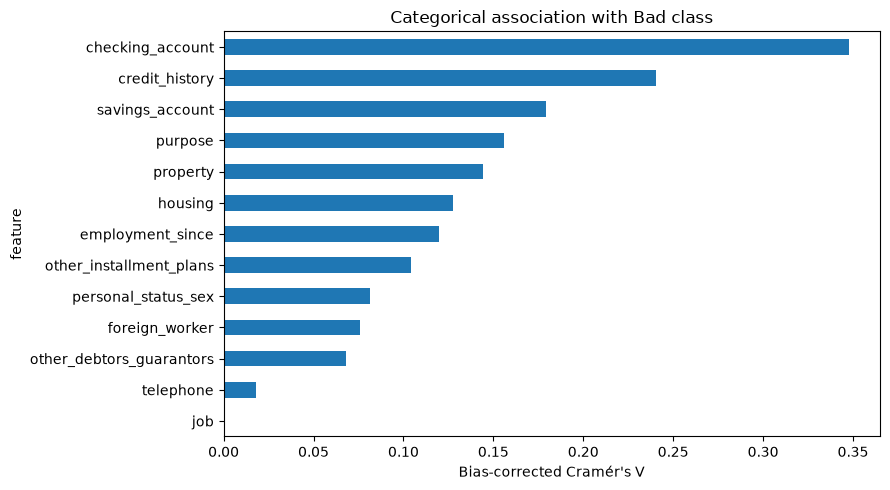

In [8]:
def cramers_v(x, y):
    tab=pd.crosstab(x,y)
    chi2, p, dof, expected=chi2_contingency(tab, correction=False)
    n=tab.to_numpy().sum(); r,k=tab.shape
    phi2=chi2/n
    # Bias-corrected Cramér's V (Bergsma correction)
    phi2corr=max(0, phi2-((k-1)*(r-1))/(n-1))
    rcorr=r-((r-1)**2)/(n-1); kcorr=k-((k-1)**2)/(n-1)
    denom=min(kcorr-1,rcorr-1)
    v=np.sqrt(phi2corr/denom) if denom>0 else np.nan
    return v,p, bool((expected<5).any())
assoc=[]
for col in categorical:
    v,p,sparse=cramers_v(df[col],df.target)
    assoc.append({'feature':col,'cramers_v':v,'chi2_p_unadjusted':p,'any_expected_cell_lt5':sparse})
assoc=pd.DataFrame(assoc).sort_values('cramers_v',ascending=False)
display(assoc)
fig,ax=plt.subplots(figsize=(9,5)); assoc.sort_values('cramers_v').plot.barh(x='feature',y='cramers_v',ax=ax,legend=False); ax.set_xlabel("Bias-corrected Cramér's V"); ax.set_title('Categorical association with Bad class'); plt.tight_layout(); plt.show()

Bad rates in the two strongest categorical variables

,count,bad_rate
checking_account,,
A11,274,0.492701
A12,269,0.390335
A13,63,0.222222
A14,394,0.116751


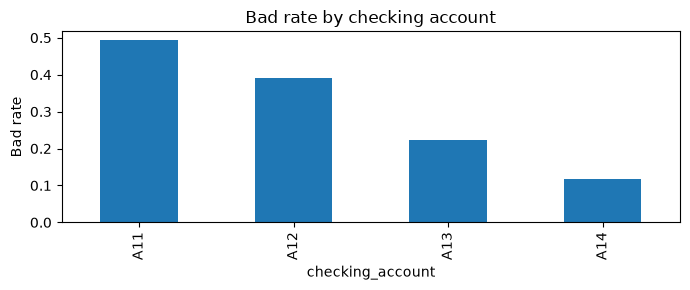

,count,bad_rate
credit_history,,
A30,40,0.625000
A31,49,0.571429
A32,530,0.318868
A33,88,0.318182
A34,293,0.170648


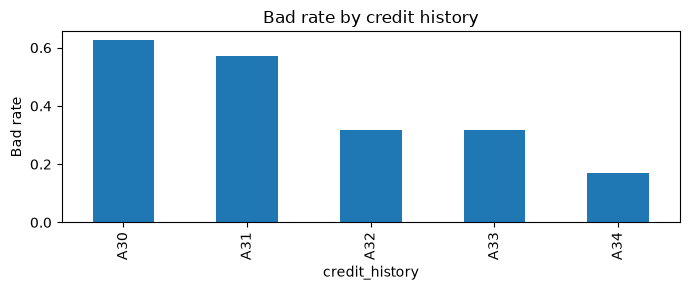

In [9]:
for col in ['checking_account','credit_history']:
    rates=df.groupby(col,observed=False).target.agg(['count','mean']).rename(columns={'mean':'bad_rate'})
    display(rates.sort_values('bad_rate',ascending=False))
    ax=rates.bad_rate.plot(kind='bar',figsize=(7,3),title=f'Bad rate by {col.replace("_"," ")}')
    ax.set_ylabel('Bad rate'); ax.set_xlabel(col); plt.tight_layout(); plt.show()

### EDA findings and interpretation
- Class distribution: 700 Good (70%) and 300 Bad (30%), an imbalance ratio of approximately 2.33:1.
- The strongest observed categorical associations are Checking Account (Cramér’s V about 0.35), Credit History (about 0.25), Savings Account (about 0.19), Purpose (about 0.18), Property (about 0.15), Employment Since (about 0.14), and Housing (about 0.14).
- Point-biserial/Pearson associations with Bad are positive for Duration (about +0.215) and Credit Amount (about +0.155), while Age is modestly negative (about −0.091). These are unadjusted associations, not causal effects.
- Duration and Credit Amount are themselves correlated (about +0.625), so their individual associations should not be interpreted as independent risk effects.
- Pearson chi-square p-values are unadjusted; sparse expected cells occur for some categories. Effect sizes and context matter more than isolated significance labels.

## 4. Feature engineering and financial meaning

Three monotonic log features were approved to reduce right-skew and express amount relative to duration. `credit_amount / duration_months` is explicitly a **principal-per-month proxy**; it is not the actual monthly installment, because interest rate, repayment schedule, fees, and amortization details are absent. No income, liabilities, debt-to-income, credit utilization, or affordability features are fabricated.

In [10]:
def engineer_features(frame):
    out=frame.copy()
    out['log_duration']=np.log1p(out['duration_months'])
    out['log_credit_amount']=np.log1p(out['credit_amount'])
    out['log_principal_per_month']=np.log1p(out['credit_amount']/out['duration_months'])
    return out.drop(columns=['duration_months','credit_amount'])

X_raw=df.drop(columns=['target_raw','target'])
y=df['target'].copy()
X=engineer_features(X_raw)
numeric_features=['installment_rate','residence_since','age_years','existing_credits','dependents',
                  'log_duration','log_credit_amount','log_principal_per_month']
feature_formula=pd.DataFrame([
 {'new_feature':'log_duration','formula':'log(1 + duration_months)','interpretation':'Compresses right-skew in duration'},
 {'new_feature':'log_credit_amount','formula':'log(1 + credit_amount)','interpretation':'Compresses right-skew in principal amount'},
 {'new_feature':'log_principal_per_month','formula':'log(1 + credit_amount / duration_months)','interpretation':'Scale proxy; not actual installment or affordability'}
])
display(feature_formula)

,new_feature,formula,interpretation
0,log_duration,log(1 + duration_months),Compresses right-skew in duration
1,log_credit_amount,log(1 + credit_amount),Compresses right-skew in principal amount
2,log_principal_per_month,log(1 + credit_amount / duration_months),Scale proxy; not actual installment or afforda...


## 5. Train/Test split and leakage-safe preprocessing

The split occurs before fitting any transformer. The holdout is stratified and used only for final evaluation. Numeric scaling and categorical one-hot encoding are placed inside a scikit-learn Pipeline, so each cross-validation fold fits its own preprocessing on that fold’s training partition. No imputation is needed because the audit found no missing values.

In [11]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=RANDOM_STATE)
print('Train:',X_train.shape, y_train.value_counts().sort_index().to_dict())
print('Test :',X_test.shape, y_test.value_counts().sort_index().to_dict())
preprocessor=ColumnTransformer([
    ('num',RobustScaler(),numeric_features),
    ('cat',OneHotEncoder(handle_unknown='ignore'),categorical)
])
def make_pipeline(estimator):
    return Pipeline([('preprocess',preprocessor),('model',estimator)])

Train: (800, 21) {0: 560, 1: 240}
Test : (200, 21) {0: 140, 1: 60}


## 6. Baseline and challenger models — stratified 5-fold CV

Decision Tree is the interpretable baseline; Random Forest is the ensemble challenger; Logistic Regression is a linear probabilistic benchmark. Reported precision/recall/F1 use the library default threshold 0.50 in this CV comparison. ROC-AUC and average precision (PR-AUC) evaluate ranking across thresholds.

In [12]:
models={
 'Decision Tree':DecisionTreeClassifier(max_depth=3,min_samples_leaf=20,random_state=RANDOM_STATE),
 'Random Forest':RandomForestClassifier(n_estimators=500,min_samples_leaf=5,random_state=RANDOM_STATE,n_jobs=-1),
 'Logistic Regression':LogisticRegression(C=1.0,max_iter=3000,random_state=RANDOM_STATE)
}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
scoring={'roc_auc':'roc_auc','pr_auc':'average_precision','precision':'precision','recall':'recall','f1':'f1','balanced_accuracy':'balanced_accuracy'}
cv_rows=[]
for name,est in models.items():
    scores=cross_validate(make_pipeline(est),X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1,return_train_score=False)
    row={'model':name}
    for metric in scoring:
        row[metric+'_mean']=scores['test_'+metric].mean()
        row[metric+'_std']=scores['test_'+metric].std()
    cv_rows.append(row)
cv_results=pd.DataFrame(cv_rows).sort_values('roc_auc_mean',ascending=False)
display(cv_results.round(4))

,model,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std
1,Random Forest,0.8000,0.0398,0.6400,0.0806,0.7254,0.1232,0.3000,0.1059,0.4165,0.1180,0.6259,0.0543
2,Logistic Regression,0.7724,0.0539,0.6021,0.0639,0.5940,0.1040,0.4750,0.0972,0.5260,0.0951,0.6679,0.0593
0,Decision Tree,0.6842,0.0795,0.4371,0.0683,0.4666,0.0866,0.2792,0.1573,0.3320,0.1386,0.5753,0.0593


### Hyperparameter tuning requirement (training data only)

A bounded grid search is provided for Random Forest using stratified 5-fold ROC-AUC. It is a separate training-only sensitivity exercise. The approved benchmark configuration above remains frozen for reproducing the prior approved results; the grid-search winner is not silently substituted into the holdout report. A new model selection after seeing the holdout would invalidate the holdout as an unbiased final assessment.

In [13]:
rf_search=GridSearchCV(
    make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=-1)),
    param_grid={
        'model__n_estimators':[300],
        'model__max_depth':[None,8],
        'model__min_samples_leaf':[5,10],
        'model__max_features':['sqrt']
    },
    scoring='roc_auc',cv=cv,n_jobs=-1,refit=True,return_train_score=False
)
rf_search.fit(X_train,y_train)
print('Training-only best CV ROC-AUC:',round(rf_search.best_score_,4))
print('Training-only best parameters:',rf_search.best_params_)

Training-only best CV ROC-AUC: 0.7994
Training-only best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 300}


## 7. Threshold choice, confusion matrix, and asymmetric business cost

The approved operating threshold 0.216 is applied unchanged to the holdout. It was selected in the prior approved analysis using training out-of-fold predictions; the exact saved OOF vector and search trace were not included with the artifacts, so the threshold-selection event itself cannot be independently reconstructed here. This section reproduces the holdout results at both 0.50 and 0.216. Cost is `5 × FN + 1 × FP` and is only the supplied educational relative-cost score.

In [14]:
rf_pipeline=make_pipeline(models['Random Forest'])
rf_pipeline.fit(X_train,y_train)
test_probability=rf_pipeline.predict_proba(X_test)[:,1]

def evaluate_threshold(y_true,prob,threshold):
    pred=(prob>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    return {'threshold':threshold,'ROC_AUC':roc_auc_score(y_true,prob),
      'PR_AUC':average_precision_score(y_true,prob),'Precision_Bad':precision_score(y_true,pred,zero_division=0),
      'Recall_Bad':recall_score(y_true,pred,zero_division=0),'F1_Bad':f1_score(y_true,pred,zero_division=0),
      'Specificity':tn/(tn+fp),'Balanced_Accuracy':balanced_accuracy_score(y_true,pred),
      'TN':tn,'FP':fp,'FN':fn,'TP':tp,'Weighted_Error_Cost':COST_FN*fn+COST_FP*fp}

threshold_results=pd.DataFrame([evaluate_threshold(y_test,test_probability,t) for t in [.50,APPROVED_RF_THRESHOLD]])
display(threshold_results.round(4))

,threshold,ROC_AUC,PR_AUC,Precision_Bad,Recall_Bad,F1_Bad,Specificity,Balanced_Accuracy,TN,FP,FN,TP,Weighted_Error_Cost
0,0.500,0.805,0.6703,0.7037,0.3167,0.4368,0.9429,0.6298,132,8,41,19,213
1,0.216,0.805,0.6703,0.4219,0.9000,0.5745,0.4714,0.6857,66,74,6,54,104


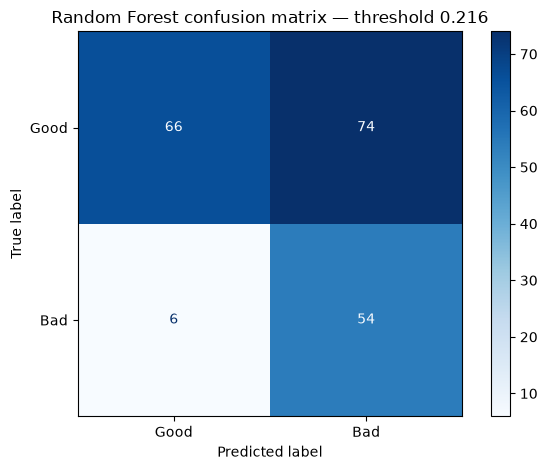

              precision    recall  f1-score   support

        Good       0.92      0.47      0.62       140
         Bad       0.42      0.90      0.57        60

    accuracy                           0.60       200
   macro avg       0.67      0.69      0.60       200
weighted avg       0.77      0.60      0.61       200



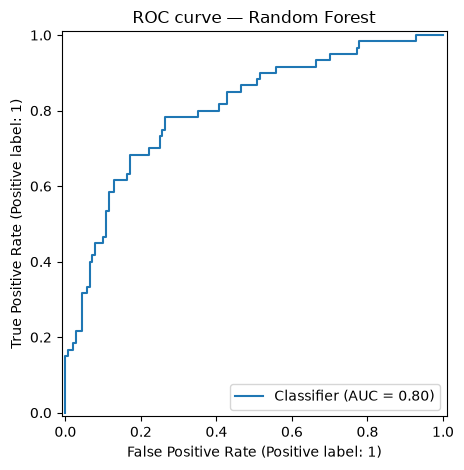

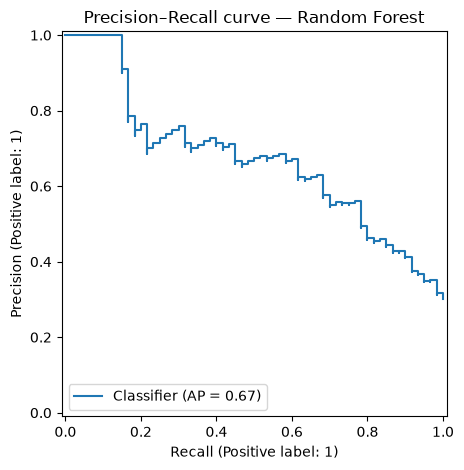

In [15]:
chosen_pred=(test_probability>=APPROVED_RF_THRESHOLD).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test,chosen_pred,display_labels=['Good','Bad'],values_format='d',cmap='Blues')
plt.title(f'Random Forest confusion matrix — threshold {APPROVED_RF_THRESHOLD:.3f}'); plt.tight_layout(); plt.show()
print(classification_report(y_test,chosen_pred,target_names=['Good','Bad'],zero_division=0))
RocCurveDisplay.from_predictions(y_test,test_probability); plt.title('ROC curve — Random Forest'); plt.tight_layout(); plt.show()
PrecisionRecallDisplay.from_predictions(y_test,test_probability); plt.title('Precision–Recall curve — Random Forest'); plt.tight_layout(); plt.show()

### Business interpretation
At threshold 0.50 the holdout confusion matrix is TN=132, FP=8, FN=41, TP=19, with cost 213. At threshold 0.216 it is TN=66, FP=74, FN=6, TP=54, with cost 104. Bad-class recall rises from 31.67% to 90.00%, while precision is 42.19% and specificity falls to 47.14%. In practical terms, the lower threshold catches many more Bad cases but falsely flags 74 of 140 Good applicants. The cost score improves under the supplied 5:1 ratio; this is not an unqualified business improvement, and it does not establish acceptable customer impact or profitability. The test set contains only 60 Bad cases, so each additional correctly detected Bad case changes recall by 1.67 percentage points.

## 8. Explainability with SHAP — global and local

SHAP is applied to the fitted Random Forest and the transformed test matrix. The global view aggregates one-hot columns back to their original source feature so the report can compare feature families. A beeswarm and bar plot provide global summaries. Two local cases are shown: a correctly flagged Bad case (true positive) and a missed Bad case (false negative). These are model explanations, not causal explanations or lawful adverse-action reason codes.

In [16]:
import shap
fitted_pre=rf_pipeline.named_steps['preprocess']
X_test_transformed=fitted_pre.transform(X_test)
if hasattr(X_test_transformed,'toarray'):
    X_test_dense=X_test_transformed.toarray()
else:
    X_test_dense=np.asarray(X_test_transformed)
feature_names=fitted_pre.get_feature_names_out()
explainer=shap.TreeExplainer(rf_pipeline.named_steps['model'])
raw_shap=explainer.shap_values(X_test_dense)
if isinstance(raw_shap,list):
    shap_bad=np.asarray(raw_shap[1])
else:
    raw_shap=np.asarray(raw_shap)
    shap_bad=raw_shap[:,:,1] if raw_shap.ndim==3 else raw_shap
assert shap_bad.shape==(len(X_test),len(feature_names)), (shap_bad.shape,len(feature_names))

c:\Users\personal-lap\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Aggregate absolute SHAP values for one-hot columns into their original source field

In [17]:
source_names=[]
for name in feature_names:
    stripped=name.split('__',1)[-1]
    if stripped in numeric_features:
        source=stripped
    else:
        source=next((c for c in categorical if stripped.startswith(c+'_')),stripped)
    source_names.append(source)
shap_long=pd.DataFrame(np.abs(shap_bad),columns=feature_names)
global_importance=pd.DataFrame({'source_feature':source_names,'mean_abs_shap':np.abs(shap_bad).mean(axis=0)})
global_importance=global_importance.groupby('source_feature',as_index=False).mean_abs_shap.sum().sort_values('mean_abs_shap',ascending=False)
display(global_importance.head(15))

,source_feature,mean_abs_shap
1,checking_account,0.105179
11,log_duration,0.030824
19,savings_account,0.029913
2,credit_history,0.028842
16,property,0.022265
12,log_principal_per_month,0.021651
17,purpose,0.020710
10,log_credit_amount,0.020163
4,employment_since,0.019705
14,other_installment_plans,0.019047


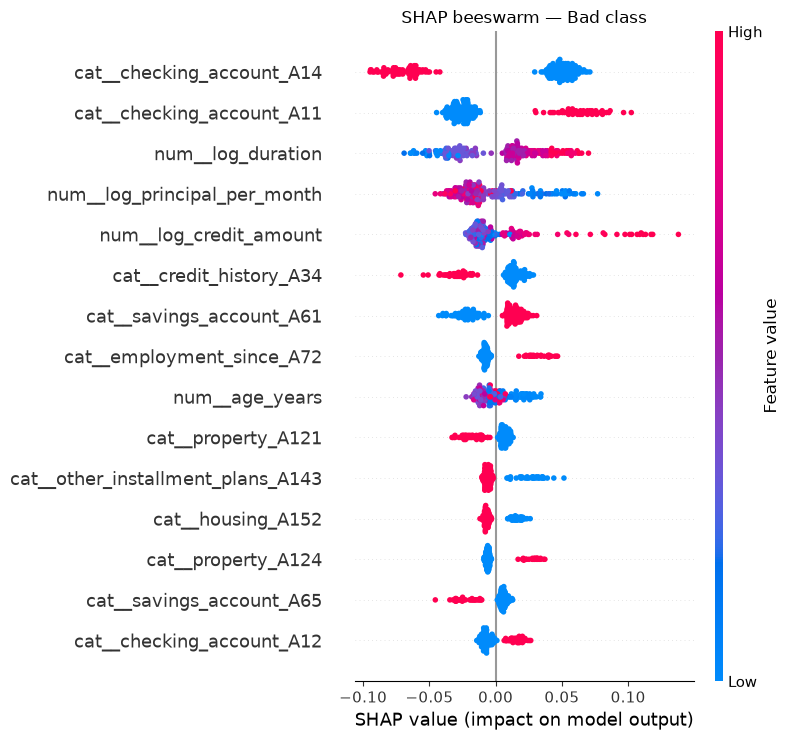

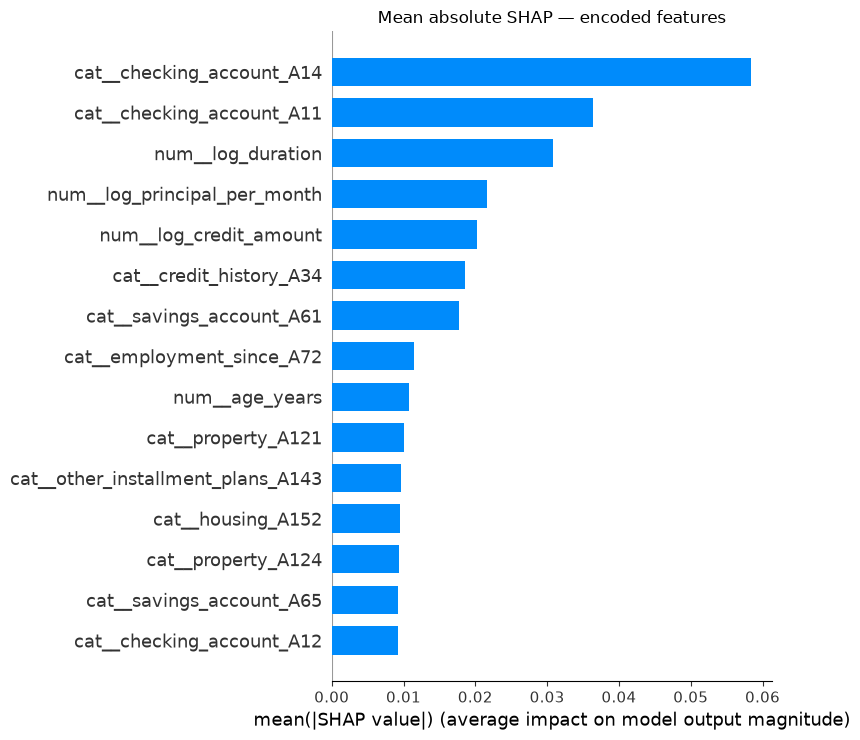

In [18]:
shap.summary_plot(shap_bad,X_test_dense,feature_names=feature_names,show=False,max_display=15)
plt.title('SHAP beeswarm — Bad class'); plt.tight_layout(); plt.show()
shap.summary_plot(shap_bad,X_test_dense,feature_names=feature_names,plot_type='bar',show=False,max_display=15)
plt.title('Mean absolute SHAP — encoded features'); plt.tight_layout(); plt.show()

Identify local examples in the untouched test partition and draw compact grouped waterfall-style plots.

High-risk case — predicted Bad (TP) | original row index: 528 | P(Bad): 0.6762 | actual: 1


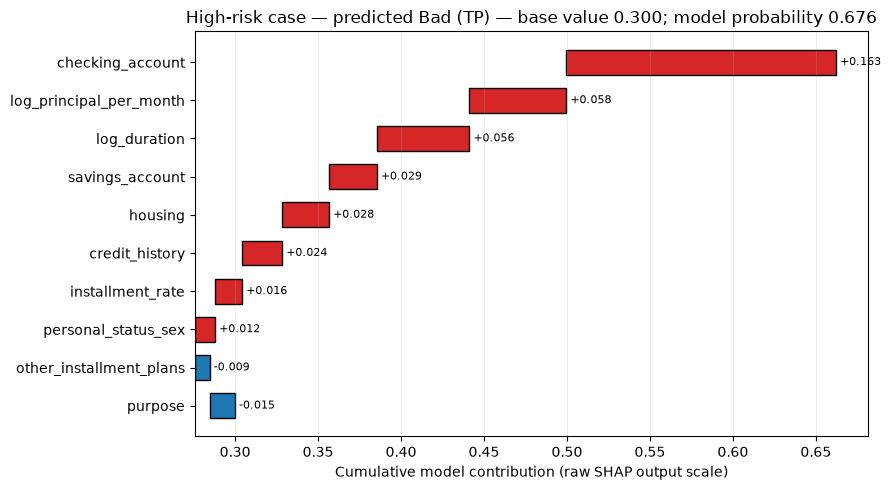

Low-risk case — predicted Good (TN) | original row index: 234 | P(Bad): 0.039 | actual: 0


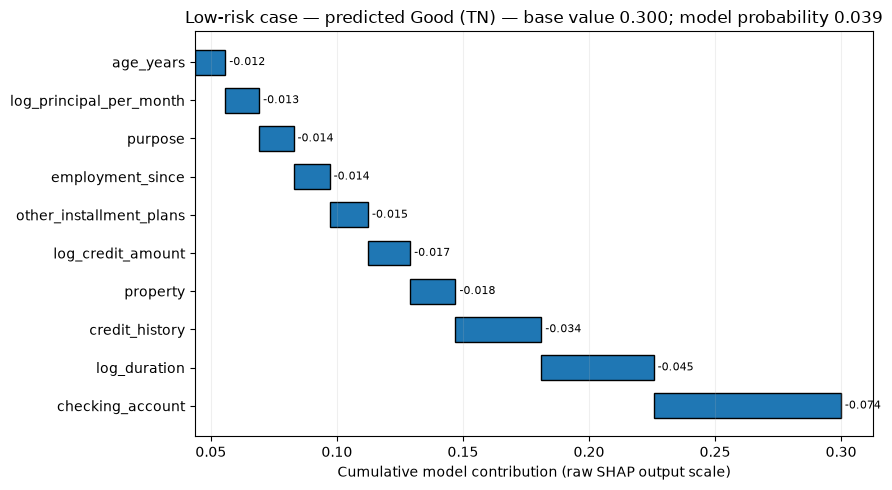

Missed Bad case — predicted Good (FN) | original row index: 228 | P(Bad): 0.091 | actual: 1


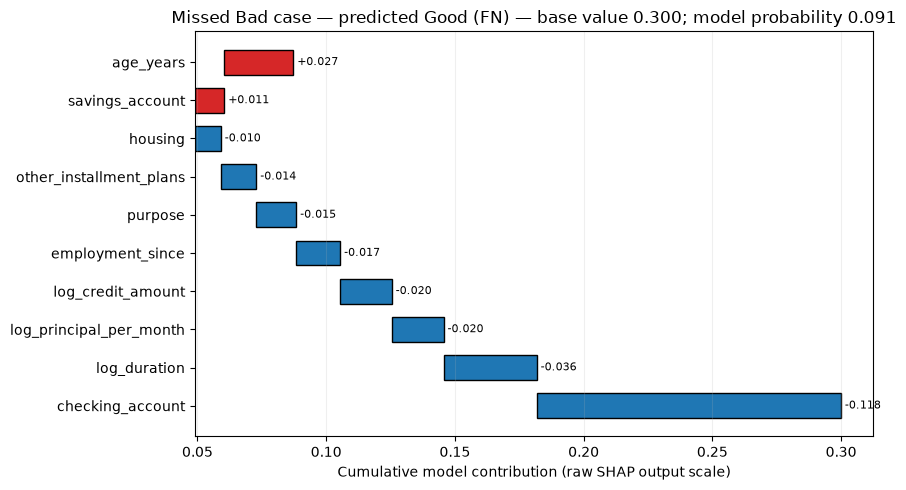

In [19]:
case_frame=pd.DataFrame({'actual':y_test.to_numpy(),'predicted':chosen_pred,'probability_bad':test_probability},index=X_test.index)
tp_candidates=case_frame[(case_frame.actual==1)&(case_frame.predicted==1)].sort_values('probability_bad',ascending=False)
tn_candidates=case_frame[(case_frame.actual==0)&(case_frame.predicted==0)].sort_values('probability_bad',ascending=True)
fn_candidates=case_frame[(case_frame.actual==1)&(case_frame.predicted==0)].sort_values('probability_bad',ascending=True)
if len(tp_candidates)==0 or len(tn_candidates)==0 or len(fn_candidates)==0:
    raise RuntimeError('Expected TP, TN, and FN examples for local explanation.')
tp_idx=tp_candidates.index[0]; tn_idx=tn_candidates.index[0]; fn_idx=fn_candidates.index[0]
index_positions={idx:i for i,idx in enumerate(X_test.index)}
base_value=float(np.asarray(explainer.expected_value).reshape(-1)[-1])
for label,idx in [('High-risk case — predicted Bad (TP)',tp_idx),('Low-risk case — predicted Good (TN)',tn_idx),('Missed Bad case — predicted Good (FN)',fn_idx)]:
    pos=index_positions[idx]
    local=pd.DataFrame({'source_feature':source_names,'contribution':shap_bad[pos]}).groupby('source_feature').contribution.sum()
    local=local.reindex(local.abs().sort_values(ascending=False).index).head(10).sort_values()
    print(label,'| original row index:',idx,'| P(Bad):',round(float(test_probability[pos]),4),'| actual:',int(y_test.loc[idx]))
    # Waterfall-style cumulative contributions, grouped to original feature families.
    starts=base_value+local.cumsum().shift(fill_value=0)
    fig,ax=plt.subplots(figsize=(9,5))
    for j,(feature,val) in enumerate(local.items()):
        left=starts.iloc[j]
        ax.barh(j,abs(val),left=min(left,left+val),height=.65,edgecolor='black',color=('tab:red' if val>0 else 'tab:blue'))
        ax.text(max(left,left+val),j,f' {val:+.3f}',va='center',fontsize=8)
    ax.set_yticks(range(len(local)),local.index); ax.set_xlabel('Cumulative model contribution (raw SHAP output scale)')
    ax.set_title(f'{label} — base value {base_value:.3f}; model probability {test_probability[pos]:.3f}')
    ax.grid(axis='x',alpha=.2); plt.tight_layout(); plt.show()

### SHAP interpretation and caveats
The approved prior analysis found Checking Account as the strongest global feature family, followed by duration, savings, credit history, property, principal-per-month proxy, purpose, credit amount, employment duration, and other installment plans. The newly executed global aggregation above is the reproducible calculation from this notebook run; small differences from earlier summaries can occur with implementation/version differences and must be reported rather than concealed. A positive SHAP contribution pushes the model output toward the Bad class; a negative contribution pushes it away. Neither direction means the feature caused default. The local cases include a high-risk TP, a low-risk TN (the accepted/Good-class example), and a missed Bad FN for diagnostic contrast. Row indices are dataset row identifiers, not customer identities.

## 9. Causality versus correlation — analytical response

### Q1. Which variables are causes and which are merely correlated signals?
The available data do not identify causal effects. Checking-account status, credit history, savings, purpose, duration, credit amount, and age are predictive/associated signals in this historical sample. SHAP only decomposes the fitted model prediction. A plausible causal structure may include latent income stability, employment security, financial literacy, household obligations, macroeconomic conditions, lender selection, and prior repayment behavior. Several of these are not measured in this dataset and can confound observed associations. Even an adjusted regression cannot eliminate unmeasured confounding or establish temporal order. Therefore, no listed feature should be called a proven cause of default on this evidence.

### Q2. Where should a risk manager intervene?
Interventions should target mechanisms that can be measured and evaluated, not merely variables with high SHAP importance. Candidate actions for a real institution could include transparent affordability assessment using verified income and liabilities, early repayment support, payment reminders, restructuring pathways, and financial counseling. These are hypotheses for prospective evaluation, not recommendations proven by this dataset. Changing credit limits or interest rates based solely on correlational features can create feedback loops, disparate impact, adverse selection, and regulatory risk. Any intervention needs a pre-registered outcome, control/comparison design where ethical, monitoring for heterogeneous effects, and legal/compliance review.

Optional adjusted observational logistic regression with HC3 robust standard errors.
This is a descriptive adjusted-association model, not a causal estimator.

In [20]:
try:
    import statsmodels.formula.api as smf
    formula=('target ~ C(checking_account)+duration_months+C(credit_history)+C(purpose)+credit_amount+'
      'C(savings_account)+C(employment_since)+installment_rate+C(personal_status_sex)+'
      'C(other_debtors_guarantors)+residence_since+C(property)+age_years+'+
      'C(other_installment_plans)+C(housing)+existing_credits+C(job)+dependents+C(telephone)+C(foreign_worker)')
    reg=smf.logit(formula,data=df).fit(disp=False,cov_type='HC3')
    coef=reg.params; ci=reg.conf_int(); reg_table=pd.DataFrame({'OR':np.exp(coef),'CI_low':np.exp(ci[0]),'CI_high':np.exp(ci[1]),'p_value':reg.pvalues})
    display(reg_table.sort_values('p_value').head(20).round(4))
    print('N:',int(reg.nobs),'| converged:',bool(reg.mle_retvals.get('converged',False)))
except Exception as exc:
    warnings.warn(f'Adjusted logistic model could not be fit in this environment: {exc}')

,OR,CI_low,CI_high,p_value
C(checking_account)[T.A14],0.1805,0.1157,0.2816,0.0000
C(purpose)[T.A41],0.1889,0.0962,0.3711,0.0000
C(purpose)[T.A43],0.4100,0.2540,0.6619,0.0003
installment_rate,1.3911,1.1627,1.6644,0.0003
C(savings_account)[T.A65],0.3880,0.2226,0.6765,0.0008
C(credit_history)[T.A34],0.2379,0.0978,0.5788,0.0015
C(purpose)[T.A42],0.4531,0.2674,0.7678,0.0033
duration_months,1.0283,1.0093,1.0476,0.0034
credit_amount,1.0001,1.0000,1.0002,0.0061
C(other_installment_plans)[T.A143],0.5240,0.3215,0.8539,0.0095


N: 1000 | converged: True


### Duration-stratified checking-account comparison
The previously approved descriptive stratification found that the Bad rate for checking category A11 remained higher than A14 within each duration band: ≤12 months (35.87% vs 7.53%), 13–24 months (50.85% vs 12.28%), 25–36 months (57.89% vs 18.52%), and >36 months (76.92% vs 17.39%). Stratification on duration alone does not control all confounding and does not turn this into a causal result.

Recompute checking-account bad rates by duration bands from the source data

In [21]:
bins=[0,12,24,36,np.inf]; labels=['≤12','13–24','25–36','>36']
df['duration_band']=pd.cut(df.duration_months,bins=bins,labels=labels,include_lowest=True)
strat=(df[df.checking_account.isin(['A11','A14'])]
       .groupby(['duration_band','checking_account'],observed=False).target.agg(['count','mean']).reset_index()
       .rename(columns={'mean':'bad_rate'}))
display(strat)

,duration_band,checking_account,count,bad_rate
0,≤12,A11,92,0.358696
1,≤12,A14,146,0.075342
2,13–24,A11,118,0.508475
3,13–24,A14,171,0.122807
4,25–36,A11,38,0.578947
5,25–36,A14,54,0.185185
6,>36,A11,26,0.769231
7,>36,A14,23,0.173913


## 10. Optional advanced component — LLM and Adverse Action

This section fulfills the assignment’s optional conceptual deliverable. No external LLM was connected or evaluated in the project. The following prompt is a proposed controlled interface; the sample response is illustrative and must not be presented as a real customer explanation. A deployed process would require validated reason codes, legal mapping, audit logs, human review, and a prohibition on the model inventing or causalizing explanations.

### Proposed prompt template

> **Role:** You are a plain-language explanation assistant. You do not make, change, or recommend a credit decision.
>
> **Inputs:** (1) the final decision status already made by the authorized decision engine; (2) only verified adverse-action reason codes approved by Compliance; (3) the direction and magnitude of validated feature contributions for the individual case; (4) approved customer guidance and contact channels.
>
> **Rules:** Use only supplied facts. Do not infer income, debt, intent, reliability, or personal circumstances. Do not claim that a feature caused default. Do not mention protected or legally restricted attributes unless the compliance-approved notice explicitly requires it. Do not invent a reason code or improvement action. If the evidence is missing or inconsistent, return `HUMAN_REVIEW_REQUIRED`. Explain that model factors are signals used in this assessment, not proof of future behavior. Keep the language respectful, specific, and understandable.
>
> **Output:** (A) short explanation tied to approved reason codes; (B) practical steps only from the approved guidance library; (C) uncertainty/limitations note; (D) escalation/contact route; (E) evidence fields used.

### Illustrative sample response (not a real applicant notice)

“Your application was not approved under the lender’s current assessment. The review identified factors in the information supplied with your application that did not meet the lender’s current criteria. These factors are assessment signals and do not establish that you will miss a payment. If you believe any information is incorrect, please contact the lender to request a review. The lender can explain the specific, legally approved reasons for this decision and the information used. Any steps you may take depend on your circumstances; please do not take on additional borrowing solely to change an automated score.”

This sample is intentionally generic because a legally valid adverse-action notice cannot be generated from unverified SHAP values alone. The required customer-specific reason codes and approved action library were not supplied.

## 11. Limitations, fairness, governance, and responsible use

1. **Historical sample:** 1,000 records; external validity to current applicants, markets, and underwriting processes is unknown.
2. **Target ambiguity:** the supplied target is a historical Good/Bad class, not a fully specified modern default event with a defined observation window.
3. **Missing financial fundamentals:** no verified income, liabilities, debt-to-income ratio, utilization, detailed repayment schedule, or complete payment history.
4. **Cost assumptions:** 5:1 FN:FP is an educational relative penalty, not full expected loss, revenue, capital, or customer-harm accounting.
5. **Small holdout event count:** 60 Bad cases; recall is sensitive to a few observations.
6. **Fairness:** `personal_status_sex` and `foreign_worker`, as well as proxies, require careful legal and subgroup fairness review. This notebook does not certify fairness or compliance.
7. **Calibration and drift:** calibration, temporal validation, external validation, drift monitoring, and reject-inference issues are not resolved.
8. **Explainability:** SHAP explains model output, not causation or legally sufficient adverse-action reasons.
9. **LLM:** conceptual only; no live model test or customer-facing deployment occurred.

**Recommendation:** retain the Random Forest at threshold 0.216 as the preferred *educational experimental candidate* under the stated cost matrix, not as a real credit policy. Before any operational consideration, require temporal/external validation, calibration, robust cost analysis, fairness assessment, human governance, and jurisdiction-specific legal/compliance approval.